Chargement des données...


c:\Users\admin\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\openpyxl\worksheet\_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)



 RÉSULTATS DE PERFORMANCE ET RISQUE
Rendement Annuel GMV   : 6.92% | S&P 500 : 9.72%
Volatilité Annuelle GMV: 12.91% | S&P 500 : 18.18%
Ratio de Sharpe GMV    : 0.54  | S&P 500 : 0.53
Max Drawdown GMV       : -36.53% | S&P 500 : -56.78%



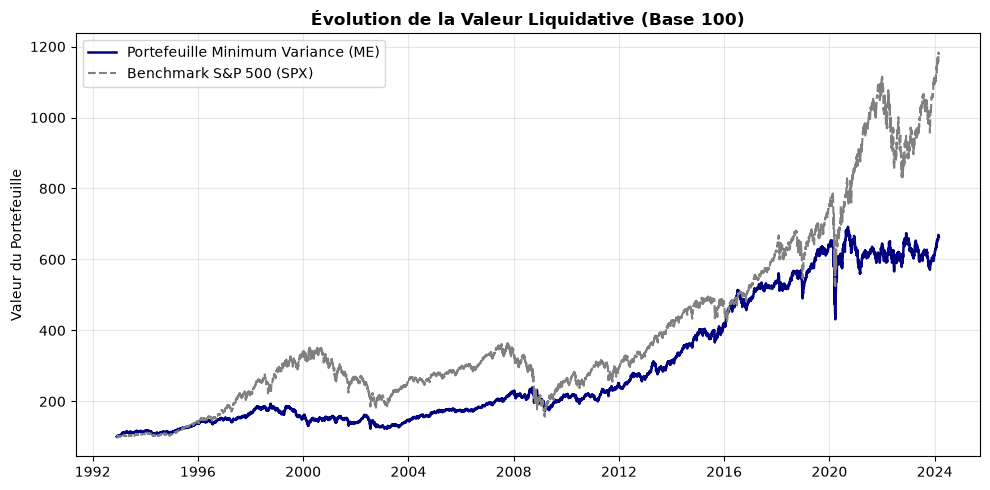

Fichier 'Historique_Poids_Secteurs.xlsx' généré avec succès !


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. PARAMÈTRES DE LA STRATÉGIE
# ==========================================
EXCEL_FILE = '../data/Data_SP.xlsx'
REBAL_FREQ = 'ME'      # 'ME' = Mensuel ('QE' = Trimestriel, 'YE' = Annuel)
LOOKBACK_DAYS = 252    # Fenêtre historique (1 an)

# ==========================================
# 2. CHARGEMENT ET NETTOYAGE DES DONNÉES
# ==========================================
def parse_excel_dates(series):
    def convert_val(val):
        if pd.isna(val):
            return np.nan
        if isinstance(val, (int, float)):
            return pd.to_datetime('1899-12-30') + pd.to_timedelta(val, unit='D')
        return pd.to_datetime(val, errors='coerce')
    return series.apply(convert_val)

print("Chargement des données...")
df_raw = pd.read_excel(EXCEL_FILE, sheet_name='Données', header=None)

clean_series = {}
for col_idx in range(0, df_raw.shape[1], 3):
    name_cell = str(df_raw.iloc[0, col_idx])
    if name_cell in ['nan', 'None']:
        continue
    ticker = name_cell.replace(' Index', '').strip()
    
    dates_col = parse_excel_dates(df_raw.iloc[3:, col_idx])
    prices_col = pd.to_numeric(df_raw.iloc[3:, col_idx+1], errors='coerce')
    
    df_temp = pd.DataFrame({'Date': dates_col, 'Price': prices_col}).dropna()
    df_temp = df_temp.drop_duplicates(subset=['Date']).sort_values('Date')
    clean_series[ticker] = df_temp.set_index('Date')['Price']

df_prices = pd.DataFrame(clean_series).dropna(how='all')

# Actifs sectoriels et SPX
assets = [c for c in df_prices.columns if c != 'SPX']
df_assets = df_prices[assets].dropna(how='all')
returns = df_assets.pct_change().dropna(how='all')

# ==========================================
# 3. CALCUL DES POIDS (MINIMUM VARIANCE)
# ==========================================
def calculate_gmv_weights(cov_matrix):
    inv_cov = np.linalg.pinv(cov_matrix)
    ones = np.ones(cov_matrix.shape[0])
    return inv_cov.dot(ones) / (ones.T.dot(inv_cov).dot(ones))

rebal_dates = returns.resample(REBAL_FREQ).last().index

weights_list = []
valid_dates = []

for date in rebal_dates:
    sub_returns = returns.loc[:date].tail(LOOKBACK_DAYS).dropna(axis=1, how='any')
    if len(sub_returns) < LOOKBACK_DAYS * 0.8 or sub_returns.shape[1] < 2:
        continue
    
    w = calculate_gmv_weights(sub_returns.cov().values)
    weights_list.append(pd.Series(w, index=sub_returns.columns))
    valid_dates.append(date)

weights_df = pd.DataFrame(weights_list, index=valid_dates).fillna(0)

# ==========================================
# 4. BACKTEST ET CALCUL DES PERFORMANCES
# ==========================================
daily_returns = df_assets.pct_change()
port_returns = []
current_w = None

for d in daily_returns.index:
    if d in weights_df.index:
        current_w = weights_df.loc[d]
    if current_w is not None:
        r = daily_returns.loc[d, current_w.index]
        port_returns.append(pd.Series({'Date': d, 'Return': (r * current_w).sum()}))

df_port_ret = pd.DataFrame(port_returns).set_index('Date').dropna()
spx_ret = df_prices['SPX'].pct_change().loc[df_port_ret.index]

# Valeurs liquidatives (Base 100)
cum_port = (1 + df_port_ret['Return']).cumprod() * 100
cum_spx = (1 + spx_ret).cumprod() * 100

# Indicateurs de performance & risque
def get_metrics(ret_series):
    ann_ret = (1 + ret_series.mean())**252 - 1
    ann_vol = ret_series.std() * np.sqrt(252)
    sharpe = ann_ret / ann_vol
    cum = (1 + ret_series).cumprod()
    max_dd = ((cum - cum.cummax()) / cum.cummax()).min()
    return ann_ret, ann_vol, sharpe, max_dd

p_ret, p_vol, p_sr, p_mdd = get_metrics(df_port_ret['Return'])
s_ret, s_vol, s_sr, s_mdd = get_metrics(spx_ret)

print("\n" + "="*50)
print(" RÉSULTATS DE PERFORMANCE ET RISQUE")
print("="*50)
print(f"Rendement Annuel GMV   : {p_ret:.2%} | S&P 500 : {s_ret:.2%}")
print(f"Volatilité Annuelle GMV: {p_vol:.2%} | S&P 500 : {s_vol:.2%}")
print(f"Ratio de Sharpe GMV    : {p_sr:.2f}  | S&P 500 : {s_sr:.2f}")
print(f"Max Drawdown GMV       : {p_mdd:.2%} | S&P 500 : {s_mdd:.2%}")
print("="*50 + "\n")

# ==========================================
# 5. GRAPHIQUE UNIQUE (ÉVOLUTION DU PORTEFEUILLE)
# ==========================================
plt.figure(figsize=(10, 5))
plt.plot(cum_port.index, cum_port, label=f'Portefeuille Minimum Variance ({REBAL_FREQ})', color='navy', lw=1.8)
plt.plot(cum_spx.index, cum_spx, label='Benchmark S&P 500 (SPX)', color='gray', linestyle='--', lw=1.5)
plt.title('Évolution de la Valeur Liquidative (Base 100)', fontsize=12, fontweight='bold')
plt.ylabel('Valeur du Portefeuille')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# ==========================================
# 6. EXPORT DE L'HISTORIQUE DES POIDS DANS EXCEL
# ==========================================
poids_table = (weights_df * 100).round(2)
poids_table.index = poids_table.index.strftime('%Y-%m')
poids_table.to_excel("../resultats/Historique_Poids_Secteurs_empirique.xlsx")

print("Fichier 'Historique_Poids_Secteurs.xlsx' généré avec succès !")